# 06 — Correlação: câmbio, crédito e comércio exterior

Passo 4 do roteiro de EDA (`docs/02_roteiro_eda.md`): matriz de correlação entre `cambio_venda`, `credito_total`, `exportação_fob` e `importação_fob` — **primeiro indício, não prova**, da relação que o objetivo geral do projeto busca.

Usa o recorte `painel_credito` (2015-01 a 2025-09) decidido no `05_tratamento_nans.ipynb`, já sem os 3 meses de NaN em `credito_total`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

painel = pd.read_csv('https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/data/processed/painel_2015_2025.csv')
painel['data'] = pd.to_datetime(painel['ano'].astype(str) + '-' + painel['mes'].astype(str) + '-01')

# recorte decidido no 05_tratamento_nans.ipynb: 2015-01 a 2025-09, sem NaN nas colunas ESTBAN
painel_credito = painel[painel['data'] <= '2025-09-01'].copy()
print(f"painel_credito: {len(painel_credito)} meses, NaNs restantes: {painel_credito.isna().sum().sum()}")

painel_credito: 129 meses, NaNs restantes: 0


## 1. Matriz de correlação

As 4 variáveis do passo 4, mais `exportação_kg`/`importação_kg` como contexto extra (mesmo par de comércio exterior, mas em volume físico em vez de valor — útil pra ver se a correlação com câmbio muda de intensidade entre valor e peso).

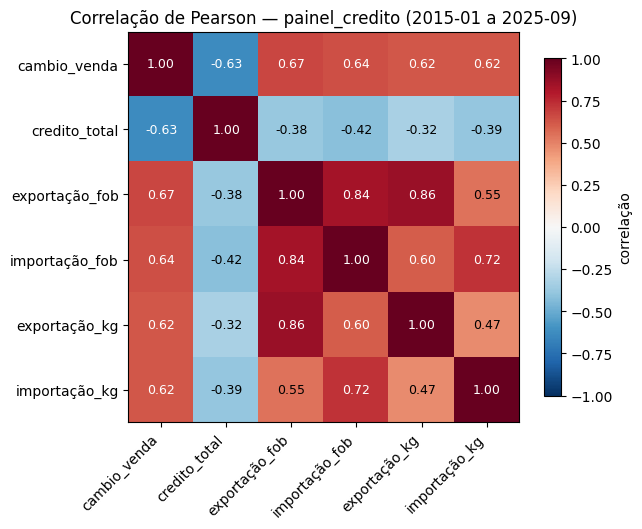

In [2]:
colunas = ['cambio_venda', 'credito_total', 'exportação_fob', 'importação_fob',
           'exportação_kg', 'importação_kg']
corr = painel_credito[colunas].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(colunas)))
ax.set_yticks(range(len(colunas)))
ax.set_xticklabels(colunas, rotation=45, ha='right')
ax.set_yticklabels(colunas)
for i in range(len(colunas)):
    for j in range(len(colunas)):
        valor = corr.iloc[i, j]
        cor_texto = 'white' if abs(valor) > 0.6 else 'black'
        ax.text(j, i, f'{valor:.2f}', ha='center', va='center', color=cor_texto, fontsize=9)
ax.set_title('Correlação de Pearson — painel_credito (2015-01 a 2025-09)')
fig.colorbar(im, ax=ax, shrink=0.8, label='correlação')
plt.tight_layout()
plt.show()

## 2. O que a matriz mostra — e o que ela não prova

As 4 variáveis do passo 4 (destaque em negrito abaixo) e como elas se relacionam:

In [3]:
c4 = painel_credito[['cambio_venda', 'credito_total', 'exportação_fob', 'importação_fob']].corr()

texto = (
    f"- **`cambio_venda` × `credito_total`**: **{c4.loc['cambio_venda','credito_total']:.2f}** — negativa e moderada. "
    "Já vimos no `04_temporal` que essa correlação é dominada pela quebra de regime de 2020 (os dois sobem juntos "
    "até 2019, depois o crédito desaba e não recupera enquanto o câmbio segue alto) — não é uma relação inversa "
    "estável mês a mês.\n"
    f"- **`cambio_venda` × `exportação_fob`**: **{c4.loc['cambio_venda','exportação_fob']:.2f}** — positiva e a mais "
    "forte do grupo. Compatível com a leitura teórica (câmbio mais alto favorece exportador em reais), mas as duas "
    "séries têm tendência de fundo crescente ao longo do período (visto no `04`), o que também infla correlação "
    "sem precisar de relação causal real.\n"
    f"- **`cambio_venda` × `importação_fob`**: **{c4.loc['cambio_venda','importação_fob']:.2f}** — positiva também, "
    "o que já é menos intuitivo (câmbio alto deveria encarecer importação, não os dois subirem juntos) — mais um "
    "indício de que tendência compartilhada, não relação direta, está pesando aqui.\n"
    f"- **`credito_total` × `exportação_fob`/`importação_fob`**: **{c4.loc['credito_total','exportação_fob']:.2f}** "
    f"e **{c4.loc['credito_total','importação_fob']:.2f}** — negativas e moderadas, mesmo padrão de quebra de "
    "regime pós-2020 que aparece na relação com câmbio.\n\n"
    "**Leitura de conjunto**: toda correlação positiva aqui envolve `cambio_venda`, `exportação_fob` e "
    "`importação_fob` — as 3 séries que têm tendência de alta ao longo do painel (confirmado no `04`). "
    "`credito_total`, que teve uma quebra e não uma tendência simples, aparece negativamente correlacionada com "
    "as 3. Esse padrão é exatamente o que se espera de **regressão espúria por tendência compartilhada**, não "
    "necessariamente de uma relação causal real entre as variáveis — é por isso que o roteiro exige o passo 5 "
    "(estacionariedade) antes de qualquer conclusão mais forte: só depois de remover tendência é que uma "
    "correlação alta passa a ser evidência de verdade, em vez de artefato."
)
display(Markdown(texto))

- **`cambio_venda` × `credito_total`**: **-0.63** — negativa e moderada. Já vimos no `04_temporal` que essa correlação é dominada pela quebra de regime de 2020 (os dois sobem juntos até 2019, depois o crédito desaba e não recupera enquanto o câmbio segue alto) — não é uma relação inversa estável mês a mês.
- **`cambio_venda` × `exportação_fob`**: **0.67** — positiva e a mais forte do grupo. Compatível com a leitura teórica (câmbio mais alto favorece exportador em reais), mas as duas séries têm tendência de fundo crescente ao longo do período (visto no `04`), o que também infla correlação sem precisar de relação causal real.
- **`cambio_venda` × `importação_fob`**: **0.64** — positiva também, o que já é menos intuitivo (câmbio alto deveria encarecer importação, não os dois subirem juntos) — mais um indício de que tendência compartilhada, não relação direta, está pesando aqui.
- **`credito_total` × `exportação_fob`/`importação_fob`**: **-0.38** e **-0.42** — negativas e moderadas, mesmo padrão de quebra de regime pós-2020 que aparece na relação com câmbio.

**Leitura de conjunto**: toda correlação positiva aqui envolve `cambio_venda`, `exportação_fob` e `importação_fob` — as 3 séries que têm tendência de alta ao longo do painel (confirmado no `04`). `credito_total`, que teve uma quebra e não uma tendência simples, aparece negativamente correlacionada com as 3. Esse padrão é exatamente o que se espera de **regressão espúria por tendência compartilhada**, não necessariamente de uma relação causal real entre as variáveis — é por isso que o roteiro exige o passo 5 (estacionariedade) antes de qualquer conclusão mais forte: só depois de remover tendência é que uma correlação alta passa a ser evidência de verdade, em vez de artefato.

## Resumo do passo 4

- Matriz de correlação calculada sobre `painel_credito` (2015-01 a 2025-09), sem NaN.
- `cambio_venda` correlaciona negativamente com `credito_total` (-0,63) e positivamente com `exportação_fob`/`importação_fob` (+0,67/+0,64) — mas todas essas correlações são consistentes com tendência de fundo compartilhada (câmbio, exportação e importação sobem ao longo do período; crédito teve uma quebra em 2020), não com uma relação causal confirmada.
- Esse é o indício de primeira ordem previsto pelo roteiro — **não prova nada por si só**. A matriz de Pearson não distingue "as duas séries se movem juntas por relação real" de "as duas séries têm tendência e por isso parecem se mover juntas".
- Consequência direta para o próximo passo: como praticamente todas as séries do painel têm tendência (confirmado no `04`), o teste de estacionariedade (ADF) é obrigatório antes de qualquer regressão ou causalidade de Granger — sem isso, o risco de regressão espúria é alto, como a própria matriz já sugere.

**Próximo passo (05 do roteiro):** estacionariedade — teste de Dickey-Fuller (ADF) em cada série do `painel_credito`.